<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [Disassembly &amp; Malware Triage](https://github.com/Query-farm/vgi-disasm)

Disassemble binaries and shellcode, then triage their sections, imports, strings, and MITRE ATT&amp;CK capabilities.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-disasm/blob/main/notebooks/02_static_evidence_changes_with_the_string_filter.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-disasm/blob/main/notebooks/README.md)


## 02 · Static evidence changes with the string filter

**Can a stricter string filter make a heuristic finding disappear from view?**
First establish the structure, entry point and imports of a committed hello-world
Mach-O fixture. Then compare its extracted strings with an authored documentation
control containing recognizable command and URL text. We locate each heuristic's
supporting bytes and change only the string-length filter.

The worker reads both inputs as data. Neither the Mach-O file nor the documentation
text is executed. A heuristic match identifies a pattern; it does not establish
intent, behavior, reachability or maliciousness. An empty result is equally unable
to prove safety.

### Choose the minimum visible string length

`MIN_CHARACTERS=4` keeps printable runs with at least four characters; the experiment
uses `12`. The input bytes and the worker's `capabilities` heuristics stay fixed.
Those heuristics perform their own string extraction at a fixed minimum of four.
A display threshold must not silently redefine their evidence population.

In [1]:
MIN_CHARACTERS = 4

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.11":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.11"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, prepare, theme, prose
from IPython.display import display

check_runtime()
prepare("disasm")
import disasm_example as example

example.validate_minimum(MIN_CHARACTERS)
session = connect(globals())
theme()

### Read the pinned release and the original fixture bytes

The public v0.4.0 native release is downloaded and verified by `github-auto`.
The 49,952-byte Mach-O is copied byte-for-byte from the worker's committed
hello-world test fixture; its SHA-256 and source revision are documented in the
[guide](README.md). It is packaged as a non-executable `.bin` companion. No compiler
or local worker checkout is needed. VARCHAR inputs are paths; BLOB inputs are bytes.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'disasm' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-disasm@v0.4.0');
CREATE TABLE fixture AS SELECT content FROM read_blob('assets/hello-macho-arm64.bin');
CREATE TABLE inventory AS SELECT octet_length(content) AS file_bytes,
 disasm.main.format(content) AS format,
 disasm.main.entrypoint(content) AS entrypoint FROM fixture;
SELECT file_bytes,format.container AS container,format.arch AS arch,format.endian AS endian,
 entrypoint.vaddr AS entry_virtual_address,entrypoint.file_off AS entry_file_offset FROM inventory;

,file_bytes,container,arch,endian,entry_virtual_address,entry_file_offset
0,49952,macho,arm64,little,4294968760,1464


### Locate the entry point inside a section

The header resolves ARM64/little-endian mode and an entry address. Match that
address to the worker's section rows; do not confuse a virtual address with a
file offset. Imports record linked symbols and their source library. `_puts`
being imported is static dependency evidence; it does not show a call was reached.

In [5]:
%%sql entry_mapping <<
CREATE TABLE sections AS SELECT * FROM disasm.main.sections('assets/hello-macho-arm64.bin');
CREATE TABLE imports AS SELECT * FROM disasm.main.imports('assets/hello-macho-arm64.bin');
SELECT i.entrypoint.vaddr AS entry_address,i.entrypoint.file_off AS entry_file_offset,
 s.name,s.kind,s.exec,s.vaddr,s.file_off,s.size,
 i.entrypoint.vaddr-s.vaddr+s.file_off AS mapped_file_offset
FROM inventory i JOIN sections s ON i.entrypoint.vaddr>=s.vaddr AND i.entrypoint.vaddr<s.vaddr+s.size;


In [6]:
display(entry_mapping)
r = entry_mapping.iloc[0]
prose(f"The entry address **{int(r.entry_address)}** maps to file byte offset **{int(r.mapped_file_offset)}** in **{r['name']}**. That agrees with the worker's separate entry-point projection. The two coordinates locate the same static bytes; neither records execution.")

,entry_address,entry_file_offset,name,kind,exec,vaddr,file_off,size,mapped_file_offset
0,4294968760,1464,"__TEXT,__text",code,True,4294968760,1464,32,1464


The entry address **4294968760** maps to file byte offset **1464** in **__TEXT,__text**. That agrees with the worker's separate entry-point projection. The two coordinates locate the same static bytes; neither records execution.

In [7]:
%%sql import_inventory <<
SELECT library,name,kind FROM imports ORDER BY library,name;

In [8]:
display(import_inventory)
prose(f"The fixture lists **{len(import_inventory)} imported symbols** from **{import_inventory.library.nunique()} library**. The `_puts` import is consistent with the fixture's hello-world provenance. Import presence does not establish that the program reached a call.")

,library,name,kind
0,/usr/lib/libSystem.B.dylib,_puts,delayed
1,/usr/lib/libSystem.B.dylib,dyld_stub_binder,named


The fixture lists **2 imported symbols** from **1 library**. The `_puts` import is consistent with the fixture's hello-world provenance. Import presence does not establish that the program reached a call.

In [9]:
%%sql sections_plot <<
SELECT name,kind,size,file_off,exec,round(entropy,3) AS entropy
FROM sections ORDER BY file_off,name;

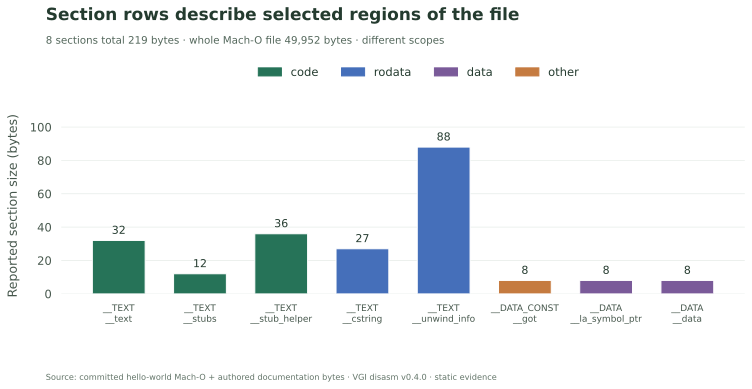

The worker reports **219 section bytes** inside a **49,952-byte file**. Headers, padding and other container data are outside these section rows; the difference is not evidence of hidden code. Executable sections describe a static container flag, not a record of execution.

In [10]:
inventory = con.execute("SELECT * FROM inventory").df()
example.section_profile(sections_plot, inventory)

### Keep the extraction population before selecting visible rows

The base extraction uses a constant minimum of one and retains both ASCII and
UTF-16LE runs. The plotted range starts at the default minimum of four, keeping
the comparison with twelve readable. A second actual worker call
uses the selected minimum. We retain both and verify that the selected output
matches filtering the base rows for these short, untruncated fixtures. The plotted
sensitivity curve is calculated locally from the base extraction; it makes no
additional worker calls. Printable runs can be names, metadata, code-adjacent data
or accidental text; a string row is not automatically a semantic field.

In [11]:
%%sql
CREATE TABLE binary_strings AS SELECT * FROM disasm.main.strings('assets/hello-macho-arm64.bin',min_len:=1);
CREATE TABLE selected_binary_strings AS SELECT * FROM disasm.main.strings('assets/hello-macho-arm64.bin',min_len:={{ MIN_CHARACTERS }});
SELECT encoding,count(*) AS selected_rows,min(length(value)) AS shortest_characters,
 max(length(value)) AS longest_characters FROM selected_binary_strings GROUP BY encoding;
SELECT "offset",encoding,value FROM selected_binary_strings ORDER BY "offset",encoding;

,offset,encoding,value
0,40,ascii,__PAGEZERO
1,112,ascii,__TEXT
2,176,ascii,__text
3,192,ascii,__TEXT
4,256,ascii,__stubs
5,272,ascii,__TEXT
6,336,ascii,__stub_helper
7,352,ascii,__TEXT
8,416,ascii,__cstring
9,432,ascii,__TEXT


### Match patterns in text that explicitly serves as documentation

The following NUL-separated BLOB is an authored documentation control. It contains
`cmd.exe /c`, a PowerShell option string, an example-domain URL and a short note.
The strings are never used as commands or destinations. The same fixed control is
passed to `strings` and `capabilities`; the Mach-O's capability output remains a
separate population. Multiple rules may match one string, so count both rule rows
and distinct supporting strings.

The join below retains every capability row even when its evidence falls below
the selected display threshold. For these short ASCII strings, exact evidence text
can be joined back to byte offsets. Long truncated evidence or repeated text in
other inputs would require additional disambiguation.

In [12]:
%%sql evidence_table <<
CREATE TABLE control_payload AS SELECT 'cmd.exe /c\x00powershell.exe -EncodedCommand ZQA=\x00http://example.invalid/help\x00notes'::BLOB AS content;
CREATE TABLE control_strings AS SELECT * FROM disasm.main.strings('cmd.exe /c\x00powershell.exe -EncodedCommand ZQA=\x00http://example.invalid/help\x00notes'::BLOB,min_len:=1);
CREATE TABLE selected_control_strings AS SELECT * FROM disasm.main.strings('cmd.exe /c\x00powershell.exe -EncodedCommand ZQA=\x00http://example.invalid/help\x00notes'::BLOB,min_len:={{ MIN_CHARACTERS }});
CREATE TABLE control_capabilities AS SELECT * FROM disasm.main.capabilities('cmd.exe /c\x00powershell.exe -EncodedCommand ZQA=\x00http://example.invalid/help\x00notes'::BLOB);
CREATE TABLE binary_capabilities AS SELECT * FROM disasm.main.capabilities('assets/hello-macho-arm64.bin');
CREATE TABLE evidence AS
 SELECT c.rule,c.attack_id,c.severity,c.evidence,s."offset" AS file_offset,
        length(s.value) AS evidence_characters,
        selected."offset" IS NOT NULL AS visible_at_selected_minimum
 FROM control_capabilities c LEFT JOIN control_strings s ON c.evidence=s.value
 LEFT JOIN selected_control_strings selected ON s."offset"=selected."offset" AND s.encoding=selected.encoding;
SELECT * FROM evidence ORDER BY file_offset,rule;


In [13]:
display(evidence_table)

,rule,attack_id,severity,evidence,file_offset,evidence_characters,visible_at_selected_minimum
0,exec:cmd,T1059.003,medium,cmd.exe /c,0,10,True
1,exec:powershell,T1059.001,medium,powershell.exe -EncodedCommand ZQA=,11,35,True
2,exec:powershell_enc,T1059.001,high,powershell.exe -EncodedCommand ZQA=,11,35,True
3,net:url,T1071,info,http://example.invalid/help,47,27,True


In [14]:
%%sql
SELECT 'Mach-O' AS sample,count(*) AS heuristic_rows FROM binary_capabilities
UNION ALL SELECT 'Documentation control',count(*) FROM control_capabilities;

,sample,heuristic_rows
0,Mach-O,0
1,Documentation control,4


In [15]:
%%sql evidence_summary <<
SELECT count(*) AS rule_rows,count(DISTINCT evidence) AS evidence_strings,
 count(*) FILTER(WHERE visible_at_selected_minimum) AS visible_rule_rows,
 count(*) FILTER(WHERE NOT visible_at_selected_minimum) AS hidden_rule_rows
FROM evidence;

In [16]:
r = evidence_summary.iloc[0]
prose(f"The authored documentation yields **{int(r.rule_rows)} heuristic rows** over **{int(r.evidence_strings)} distinct strings**. At the selected minimum, **{int(r.visible_rule_rows)} rule rows** have visible supporting text and **{int(r.hidden_rule_rows)} do not**. The fixed capability results have not changed. These advisory tags are pattern matches, not observations that a command ran or a connection occurred.")

The authored documentation yields **4 heuristic rows** over **3 distinct strings**. At the selected minimum, **4 rule rows** have visible supporting text and **0 do not**. The fixed capability results have not changed. These advisory tags are pattern matches, not observations that a command ran or a connection occurred.

In [17]:
%%sql sensitivity <<
CREATE TABLE sensitivity AS WITH sources AS (
 SELECT 'Mach-O' AS sample,* FROM binary_strings
 UNION ALL SELECT 'Documentation control',* FROM control_strings
), populations AS(SELECT DISTINCT sample FROM sources)
SELECT p.sample,m.minimum_characters,count(s.value) AS string_rows
FROM populations p CROSS JOIN range(4,25) m(minimum_characters)
LEFT JOIN sources s ON p.sample=s.sample AND length(s.value)>=m.minimum_characters
GROUP BY p.sample,m.minimum_characters ORDER BY p.sample,m.minimum_characters;
SELECT * FROM sensitivity ORDER BY sample,minimum_characters;

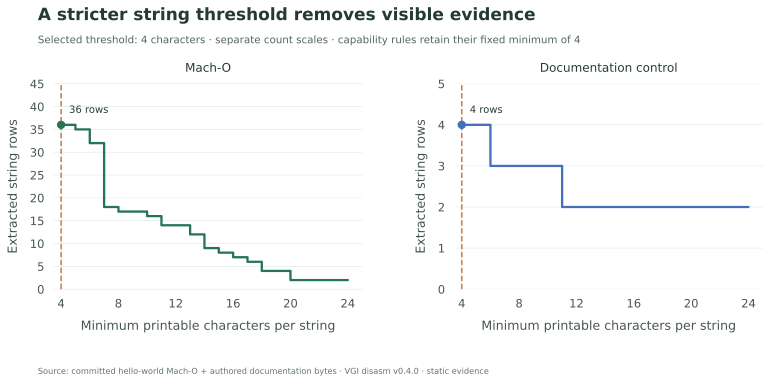

In [18]:
example.string_sensitivity(sensitivity, MIN_CHARACTERS)

### Reconcile offsets and selected populations

Check that the projected entry offset agrees with its section mapping, imports
remain present, selected extraction rows match the local threshold and every
control heuristic retains its underlying bytes. These relationships validate this
static analysis; they do not validate behavior or exhaust all possible indicators.

In [19]:
%%sql checks <<
SELECT 'Fixture bytes remain fixed' AS check_name,(SELECT file_bytes=49952 FROM inventory) AS passed
UNION ALL SELECT 'Header resolves arm64 little endian',(SELECT format.container='macho' AND format.arch='arm64' AND format.endian='little' FROM inventory)
UNION ALL SELECT 'Entry point maps to exactly one executable section',(SELECT count(*)=1 AND bool_and(s.exec AND i.entrypoint.file_off=i.entrypoint.vaddr-s.vaddr+s.file_off) FROM inventory i JOIN sections s ON i.entrypoint.vaddr>=s.vaddr AND i.entrypoint.vaddr<s.vaddr+s.size)
UNION ALL SELECT 'Eight projected sections remain present',(SELECT count(*)=8 FROM sections)
UNION ALL SELECT 'The hello-world puts import remains present',(SELECT count(*)=1 FROM imports WHERE name='_puts')
UNION ALL SELECT 'Selected Mach-O strings equal local threshold',(SELECT count(*)=0 FROM ((SELECT * FROM selected_binary_strings EXCEPT SELECT * FROM binary_strings WHERE length(value)>={{ MIN_CHARACTERS }}) UNION ALL (SELECT * FROM binary_strings WHERE length(value)>={{ MIN_CHARACTERS }} EXCEPT SELECT * FROM selected_binary_strings)))
UNION ALL SELECT 'Selected control strings equal local threshold',(SELECT count(*)=0 FROM ((SELECT * FROM selected_control_strings EXCEPT SELECT * FROM control_strings WHERE length(value)>={{ MIN_CHARACTERS }}) UNION ALL (SELECT * FROM control_strings WHERE length(value)>={{ MIN_CHARACTERS }} EXCEPT SELECT * FROM selected_control_strings)))
UNION ALL SELECT 'Every control heuristic maps to a string offset',(SELECT count(*)=0 FROM evidence WHERE file_offset IS NULL)
UNION ALL SELECT 'No duplicated heuristic rows after evidence join',(SELECT count(*) FROM evidence)=(SELECT count(*) FROM control_capabilities)
UNION ALL SELECT 'Control ASCII offsets reproduce its evidence',(SELECT bool_and(evidence=substring(decode(content),file_offset::BIGINT+1,length(evidence))) FROM evidence CROSS JOIN control_payload)
UNION ALL SELECT 'Selected rows respect the visible threshold',(SELECT count(*)=0 FROM selected_control_strings WHERE length(value)<{{ MIN_CHARACTERS }})
UNION ALL SELECT 'Both sensitivity curves are nonincreasing',(SELECT count(*)=0 FROM(SELECT *,lag(string_rows) OVER(PARTITION BY sample ORDER BY minimum_characters) AS previous_rows FROM sensitivity) WHERE string_rows>previous_rows);

In [20]:
display(checks)
assert checks.passed.eq(True).all()
prose(f"**{len(checks)} relationship checks pass.** The two input populations and original capability results stay fixed while the selected string evidence changes.")

,check_name,passed
0,Fixture bytes remain fixed,True
1,Header resolves arm64 little endian,True
2,Entry point maps to exactly one executable sec...,True
3,Eight projected sections remain present,True
4,The hello-world puts import remains present,True
5,Selected Mach-O strings equal local threshold,True
6,Selected control strings equal local threshold,True
7,Every control heuristic maps to a string offset,True
8,No duplicated heuristic rows after evidence join,True
9,Control ASCII offsets reproduce its evidence,True


**12 relationship checks pass.** The two input populations and original capability results stay fixed while the selected string evidence changes.

### Change one threshold and retain the original findings

Set `MIN_CHARACTERS` to **12**, restart and run all. Predict which documentation
string becomes invisible, then compare the evidence table and sensitivity marker.
The header, sections, imports and capability populations should remain identical.
Keep a separate experiment with:

```sh
uv run --locked vgi-notebooks 02_static_evidence_changes_with_the_string_filter.ipynb --parameters '{"MIN_CHARACTERS":12}' --output-dir artifacts/minimum-12
```

Reset to 4 afterward. This example handles short ASCII fixture strings; it does
not evaluate arbitrary Unicode, obfuscation, packed data or rule completeness.
The worker's advisory severity is not a probability. Static metadata, strings
and heuristics support investigation without proving execution or intent.

In [21]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-disasm](https://github.com/Query-farm/vgi-disasm)